# Packet tests of 2026-10-12: what the parameter changes did to the traces and images

Data: `data/2026-10-12-PA03_PQ04_Packet_Tests/`, the first run with **varied operating parameters**.
Five settings were taken one after the other. Each has 3 trace sets (board 101, 4 channels, about
33 s apart). The first four also have a synchronized image (50×130×500, 20×20 binning).

The questions:

1. **Which trace features change with which parameter?** (sections 3–5)
2. **Do the images change the same way?** (section 6)
3. **Could an ML model be trained on data like this?** (section 7)

Key figures are saved to `docs/context/figures/` (prefix `oct12_`).

In [1]:
import sys, json
from pathlib import Path
from datetime import datetime
from collections import Counter
import warnings
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)   # NaN features (cannot exist) give harmless warnings

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from trace_features import trace_features, scalar_names, FEATURES

RUN = PROJECT / "data" / "2026-10-12-PA03_PQ04_Packet_Tests"
FIGS = PROJECT / "docs" / "context" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
def save(fig, name):
    fig.savefig(FIGS / f"oct12_{name}.png", dpi=120, bbox_inches="tight")

# one colour per setting, used in every figure
LABEL = {1: "1 reference", 2: "2 VDD −20.5 V", 3: "3 V low rails & TG", 4: "4 all H low rails", 5: "5 H3_A_L only"}
COLOR = {1: "0.55", 2: "tab:orange", 3: "tab:green", 4: "tab:red", 5: "tab:purple"}
CHANNEL = {0: "ch0 (D)", 1: "ch1 (C)", 2: "ch2 (A)", 3: "ch3 (B)"}

## 1. The settings

Every acquisition's `.meta` lists all voltages and sequencer delays. Consecutive acquisitions with
the same values form one setting.

In [2]:
metas = sorted(((json.loads(p.read_text()), p) for p in RUN.glob("*.meta")), key=lambda x: x[0]["DATEini"])
KEYS = [k for k in metas[0][0] if k[:2] in ("V1", "V2", "V3", "H1", "H2", "H3", "TG", "SW", "OG", "RG", "DG")
        or k in ("VSUB", "VDD1", "VDD2", "VDRAIN1", "VDRAIN2", "VR1", "VR2") or k.startswith("delay")]
groups, sig = [], None
for m, p in metas:
    if m["ACMID"] != 101:
        continue
    s = json.dumps({k: m.get(k) for k in KEYS})
    if s != sig:
        groups.append({"settings": {k: m.get(k) for k in KEYS}, "files": []}); sig = s
    groups[-1]["files"].append((m, p))
ref = groups[0]["settings"]
changed_keys = [k for k in KEYS if any(g["settings"][k] != ref[k] for g in groups)]
print(f"{'setting':22s} {'time (UTC)':12s} " + " ".join(f"{k:>7s}" for k in changed_keys))
for g, group in enumerate(groups, start=1):
    t = group["files"][0][0]["DATEini"][11:16]
    cells_ = [f"{group['settings'][k]:7.2f}" if group["settings"][k] != ref[k] else f"{'·':>7s}" for k in changed_keys]
    print(f"{LABEL[g]:22s} {t:12s} " + " ".join(cells_))
print("\n'·' = same as the reference. Reference values:", {k: round(ref[k], 2) for k in changed_keys})

setting                time (UTC)    V1_B_L  V2_C_L  V3_B_L  TG_B_H  V1_A_L  V3_A_L  TG_A_H  TG_A_L  H1_B_L  H2_C_L  H3_B_L  H1_A_L  H3_A_L    VDD1    VDD2
1 reference            18:56              ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·
2 VDD −20.5 V          19:15              ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·  -20.52  -20.52
3 V low rails & TG     20:40           7.20    7.40    7.20    7.00    7.40    7.40    7.00    7.00       ·       ·       ·       ·       ·       ·       ·
4 all H low rails      20:59              ·       ·       ·       ·       ·       ·       ·       ·    6.00    6.20    6.00    6.20    6.20       ·       ·
5 H3_A_L only          21:09              ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·       ·    6.20       ·       ·

'·' = same as the reference. Reference values: {'V1_B_L': 7.7, 

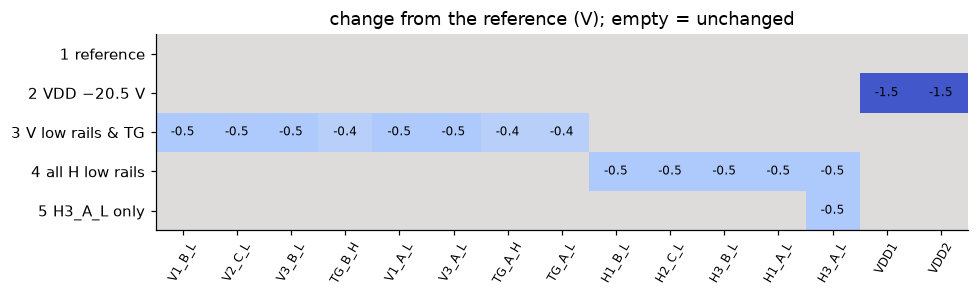

In [3]:
# the same as a picture: which parameter differs from the reference in which setting
fig, ax = plt.subplots(figsize=(9, 2.8))
M = np.array([[groups[g]["settings"][k] - ref[k] for k in changed_keys] for g in range(len(groups))])
ax.imshow(M, cmap="coolwarm", vmin=-1.6, vmax=1.6, aspect="auto")
for (i, j), v in np.ndenumerate(M):
    if v:
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(changed_keys))); ax.set_xticklabels(changed_keys, rotation=60, fontsize=8)
ax.set_yticks(range(len(groups))); ax.set_yticklabels([LABEL[g] for g in range(1, len(groups) + 1)])
ax.set_title("change from the reference (V); empty = unchanged"); ax.grid(False)
plt.tight_layout(); save(fig, "settings"); plt.show()

**Read this before the comparisons:**

* **VDD went back to −19 V after setting 2.** So settings 3, 4 and 5 each differ from the reference in
  their rails only.
* Setting 4 lowers 5 horizontal low rails, including H3_A_L. Setting 5 lowers H3_A_L only. So
  **4 vs 5 = four H low rails, nothing else**: the cleanest comparison of the run.
* **5 vs 3 = V low rails & TG** (plus H3_A_L going back up, which only touches the horizontal
  transfer).
* **VDD has no clean comparison.** 1 vs 2 changes only VDD, but setting 1's traces were taken with a
  different trace setup (section 2). 5 vs 2 has the same setup but also changes H3_A_L. A feature is
  called a VDD effect only if it changes in **both**.
* On board 101 in setting 3, TG_B_H (7.0) is **below** TG_B_L (7.4).

## 2. Trace setup and quality

In [4]:
traces = []
for g, group in enumerate(groups, start=1):
    for m, p in group["files"]:
        if p.name.startswith("trace"):
            ch = int(p.name.split("_ch")[1][0])
            traces.append(dict(group=g, ch=ch, path=p.with_suffix(f".RJ45ADCDATA{ch}"), meta=m, time=m["DATEini"]))
print("traces per setting and NCOLPRE:", sorted(Counter((t["group"], t["meta"]["NCOLPRE"]) for t in traces).items()))

traces per setting and NCOLPRE: [((1, 0), 12), ((2, 185), 12), ((3, 185), 12), ((4, 185), 12), ((5, 185), 12)]


* Setting 1's traces have `NCOLPRE = 0`. All later traces inherited `NCOLPRE = 185` from the first
  image (`take_trace.py` does not set it), so they are 1.7 s long instead of 0.8 s. **This makes
  setting 1 a poor baseline**, and is why the comparisons below use settings 2–5.
* One trace (setting 5, ch3) lost data and is refused by the quality check.

In [5]:
for t in traces:
    try:
        f = trace_features(t["path"], meta=t["meta"])
        t["features"], t["curves"] = f.scalars, f.curves
    except ValueError as err:
        t["refused"] = str(err)[:80]
traces = [t for t in traces if "features" in t]
names = scalar_names()
print(len(traces), "traces with features;", len(names), "features each")

59 traces with features; 85 features each


## 3. How to read a "separation"

Every setting has 3 trace sets, so every feature has 3 values per setting and channel. Their scatter
is the measurement noise of that feature. The **separation** of two settings is

$$\text{separation} = \frac{\text{difference of the means}}{\text{scatter between repeats}}$$

i.e. *how many times larger the change is than the noise*. Beyond about 6 the change is real (for 3
vs 3 repeats, p ≈ 0.002). Example: the lowest point of the horizontal-transfer waveform, channel 0.
Each dot is one trace set.

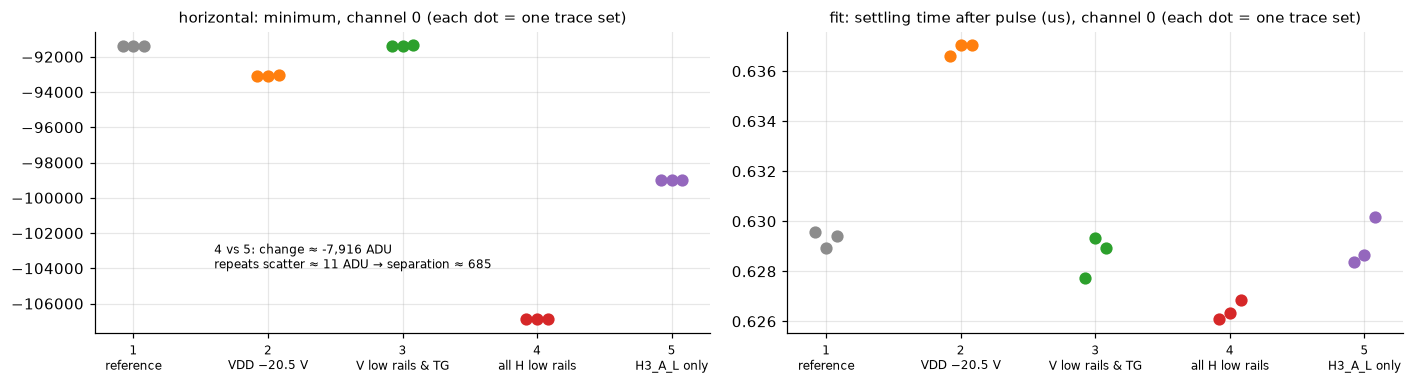

In [6]:
def values(group, ch, name):
    return np.array([t["features"][name] for t in traces if t["group"] == group and t["ch"] == ch])

def separation(a, b):
    # signed: (mean b - mean a) / pooled scatter of the repeats
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a) < 2 or len(b) < 2:
        return np.nan
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / pooled if pooled > 0 else np.nan

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, name in zip(axes, ["horizontal: minimum", "fit: settling time after pulse (us)"]):
    for g in range(1, 6):
        v = values(g, 0, name)
        ax.plot(np.full(len(v), g) + np.linspace(-0.08, 0.08, len(v)), v, "o", color=COLOR[g], ms=7)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([LABEL[g].replace(" ", "\n", 1) for g in range(1, 6)], fontsize=8)
    ax.set_title(f"{name}, channel 0 (each dot = one trace set)", fontsize=10)
s45 = separation(values(5, 0, "horizontal: minimum"), values(4, 0, "horizontal: minimum"))
axes[0].annotate(f"4 vs 5: change ≈ {np.mean(values(4, 0, 'horizontal: minimum')) - np.mean(values(5, 0, 'horizontal: minimum')):,.0f} ADU\n"
                 f"repeats scatter ≈ {np.std(values(5, 0, 'horizontal: minimum'), ddof=1):.0f} ADU → separation ≈ {abs(s45):.0f}",
                 (4.5, np.mean(values(4, 0, 'horizontal: minimum'))), fontsize=8, xytext=(1.6, -104000))
plt.tight_layout(); save(fig, "separation_example"); plt.show()

Left: the repeats agree to tens of ADU, the settings differ by thousands. Right: a subtle feature
(the amplifier's settling time). The change with VDD is only 0.008 µs, but the repeats agree to about
0.001 µs, so it is still clear.

## 4. Which features each parameter changes

For each parameter change: the features that change **in the same direction on all 4 channels**
with a separation of at least 6 (median over the channels), ranked by that separation. The number at each bar is the typical size of the change (median over the
channels).

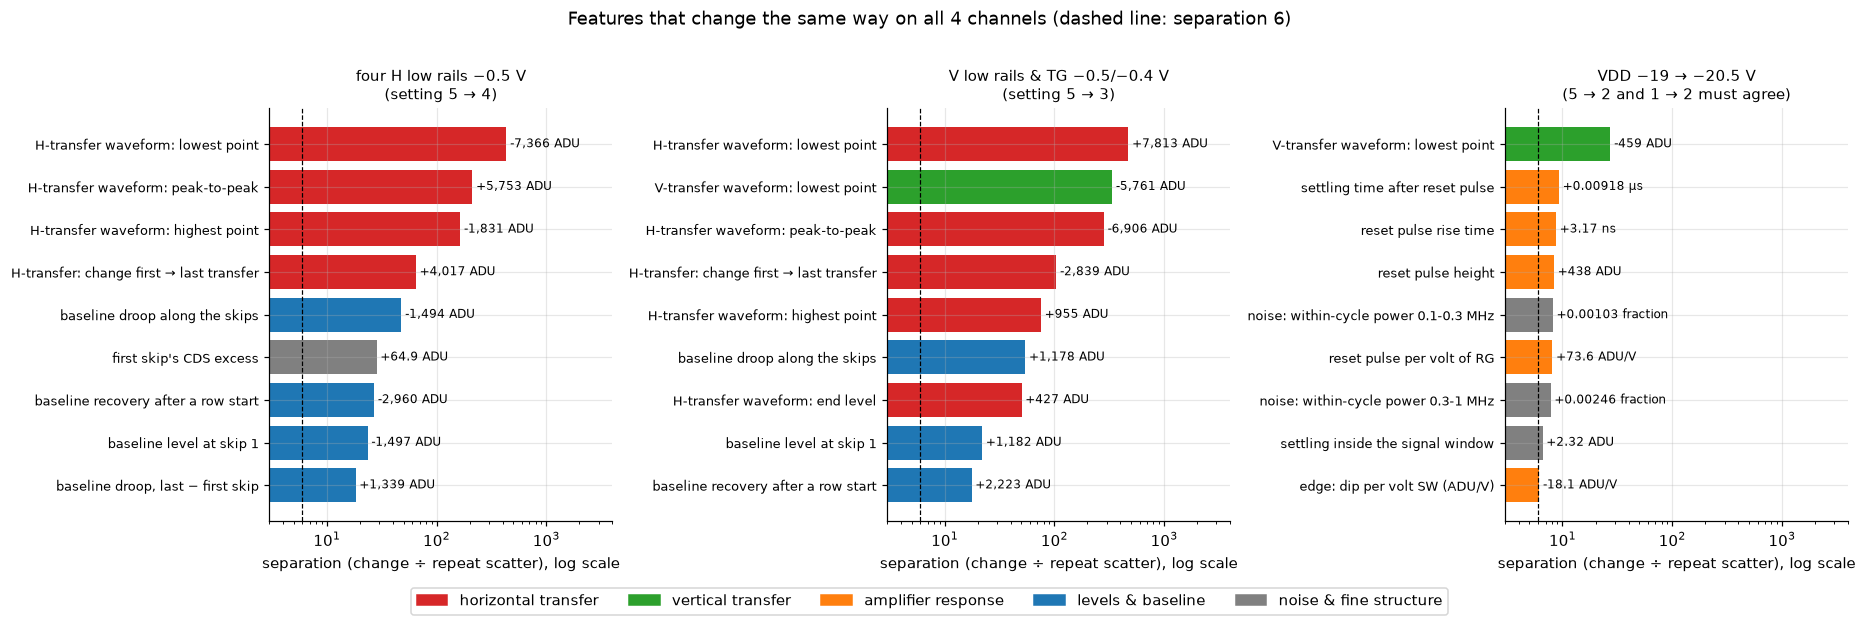

In [7]:
def region(name):
    if name.startswith(("horizontal:", "slow: H-transfer")):
        return "horizontal transfer"
    if name.startswith("vertical:"):
        return "vertical transfer"
    if name.startswith(("fit: settling", "fit: dip", "skip: pulse", "skip: dip", "edge: rise", "edge: recovery",
                        "edge: ringing", "edge: pulse", "edge: dip")):
        return "amplifier response"
    if name.startswith(("skip: baseline", "skip: droop", "fit: baseline droop", "slow: row-start", "slow: drift",
                        "skip: end-of-cycle", "skip: signal-window", "skip: CDS mean", "level:")):
        return "levels & baseline"
    return "noise & fine structure"
REGIONS = ["horizontal transfer", "vertical transfer", "amplifier response", "levels & baseline", "noise & fine structure"]
RCOLOR = dict(zip(REGIONS, ["tab:red", "tab:green", "tab:orange", "tab:blue", "0.5"]))

PLAIN = {
    "horizontal: minimum": "H-transfer waveform: lowest point",
    "horizontal: maximum": "H-transfer waveform: highest point",
    "horizontal: end level": "H-transfer waveform: end level",
    "slow: H-transfer peak-to-peak (ADU)": "H-transfer waveform: peak-to-peak",
    "slow: H-transfer first-to-last change (ADU)": "H-transfer: change first → last transfer",
    "vertical: minimum": "V-transfer waveform: lowest point",
    "vertical: maximum": "V-transfer waveform: highest point",
    "fit: baseline droop amplitude": "baseline droop along the skips",
    "skip: droop total": "baseline droop, last − first skip",
    "skip: baseline at skip 1": "baseline level at skip 1",
    "slow: row-start recovery amplitude (ADU)": "baseline recovery after a row start",
    "skip: first-skip CDS excess": "first skip's CDS excess",
    "fit: settling time after pulse (us)": "settling time after reset pulse",
    "fit: dip recovery time (us)": "recovery time after SW dip",
    "skip: pulse peak height": "reset pulse height",
    "edge: rise time (ns)": "reset pulse rise time",
    "edge: pulse per volt RG (ADU/V)": "reset pulse per volt of RG",
    "noise: signal-window settling (ADU)": "settling inside the signal window",
    "skip: CDS rms (detrended)": "CDS noise per skip",
}
def unit(name):
    return {"ADU": "ADU", "µs": "µs", "ns": "ns"}.get(FEATURES[name].unit, FEATURES[name].unit)

def compare(a, b):
    # per feature: signed separation per channel and mean change per channel
    S = np.array([[separation(values(a, ch, n), values(b, ch, n)) for n in names] for ch in range(4)])
    D = np.array([[np.nanmean(values(b, ch, n)) - np.nanmean(values(a, ch, n)) for n in names] for ch in range(4)])
    return S, D

EFFECTS = {
    "four H low rails −0.5 V\n(setting 5 → 4)": [(5, 4)],
    "V low rails & TG −0.5/−0.4 V\n(setting 5 → 3)": [(5, 3)],
    "VDD −19 → −20.5 V\n(5 → 2 and 1 → 2 must agree)": [(5, 2), (1, 2)],
}
fingerprint = {}
for label, pairs in EFFECTS.items():
    results = [compare(a, b) for a, b in pairs]
    S = np.min([np.abs(r[0]) for r in results], axis=0)                 # weakest of the comparisons
    same_sign = np.all([np.sign(r[0]) == np.sign(results[0][0]) for r in results], axis=0)
    S = np.where(same_sign, S, 0)
    signs = np.sign(results[0][0])
    consistent = np.all(signs == signs[0], axis=0)                       # same direction on all channels
    med = np.where(consistent, np.nanmedian(S, axis=0), 0)
    med = np.where(med >= 6, med, 0)
    if len(pairs) > 1:                                                   # VDD: leave out the H3_A_L features
        med = np.where([region(n) == "horizontal transfer" for n in names], 0, med)
    order = [i for i in np.argsort(-med) if med[i] > 0]
    fingerprint[label] = [(names[i], med[i], np.nanmedian(results[0][1][:, i])) for i in order]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, (label, rows) in zip(axes, fingerprint.items()):
    rows = rows[:9][::-1]
    y = np.arange(len(rows))
    ax.barh(y, [r[1] for r in rows], color=[RCOLOR[region(r[0])] for r in rows])
    for yi, (n, s, d) in zip(y, rows):
        ax.text(s * 1.08, yi, (f"{d:+,.0f}" if abs(d) >= 100 else f"{d:+.3g}") + f" {unit(n)}", va="center", fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels([PLAIN.get(r[0], r[0]) for r in rows], fontsize=8.5)
    ax.set_xscale("log"); ax.set_xlim(3, 4000); ax.axvline(6, color="k", ls="--", lw=0.8)
    ax.set_title(label, fontsize=10); ax.set_xlabel("separation (change ÷ repeat scatter), log scale")
handles = [plt.Rectangle((0, 0), 1, 1, color=RCOLOR[r]) for r in REGIONS]
fig.legend(handles, REGIONS, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Features that change the same way on all 4 channels (dashed line: separation 6)", y=1.01)
plt.tight_layout(); save(fig, "fingerprints"); plt.show()

**Each parameter leaves its own fingerprint:**

* **Horizontal low rails** change the horizontal-transfer waveform: its lowest point drops by about
  7,500 ADU, separation about 400. They also change the baseline level and its droop along the skips.
* **Vertical low rails & TG** change the vertical-transfer waveform: its lowest point drops by about
  5,800 ADU. Most horizontal-transfer features also move, but that is H3_A_L going back up between
  setting 5 and setting 3.
* **VDD** changes the **amplifier response**: the reset pulse settles more slowly (+0.008–0.01 µs),
  rises about 3 ns more slowly and is about 440 ADU higher (per volt of RG: +74 ADU/V). Nothing in the clock-transfer waveforms changes
  much, as expected for an output-stage bias.

The same in one table: how many features of each kind change on all 4 channels.

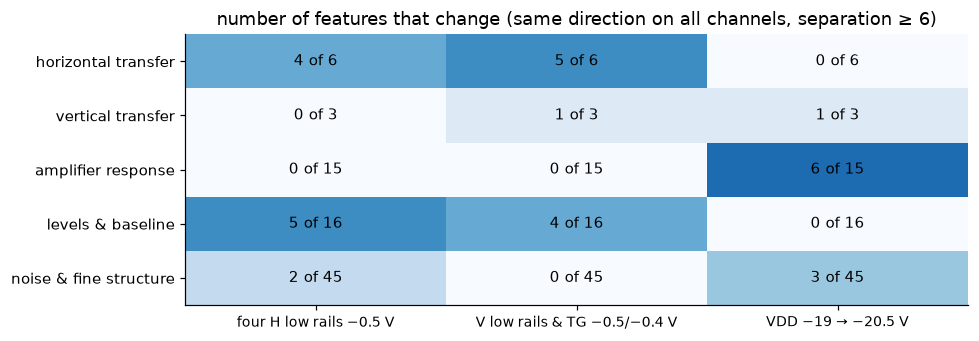

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.2))
T = np.array([[sum(region(n) == r for n, s, d in rows) for rows in fingerprint.values()] for r in REGIONS])
# (same criterion as the bar charts: same direction on all channels, median separation >= 6)
total = [sum(region(n) == r for n in names) for r in REGIONS]
ax.imshow(T, cmap="Blues", vmin=0, vmax=max(T.max(), 1) * 1.3, aspect="auto")
for (i, j), v in np.ndenumerate(T):
    ax.text(j, i, f"{v} of {total[i]}", ha="center", va="center", fontsize=10)
ax.set_xticks(range(len(fingerprint))); ax.set_xticklabels([l.split("\n")[0] for l in fingerprint], fontsize=9)
ax.set_yticks(range(len(REGIONS))); ax.set_yticklabels(REGIONS)
ax.set_title("number of features that change (same direction on all channels, separation ≥ 6)"); ax.grid(False)
plt.tight_layout(); save(fig, "feature_regions"); plt.show()

## 5. The waveforms themselves

Channel 0, average over the trace sets. Each panel shows only the two settings of one clean comparison,
with the difference shaded.

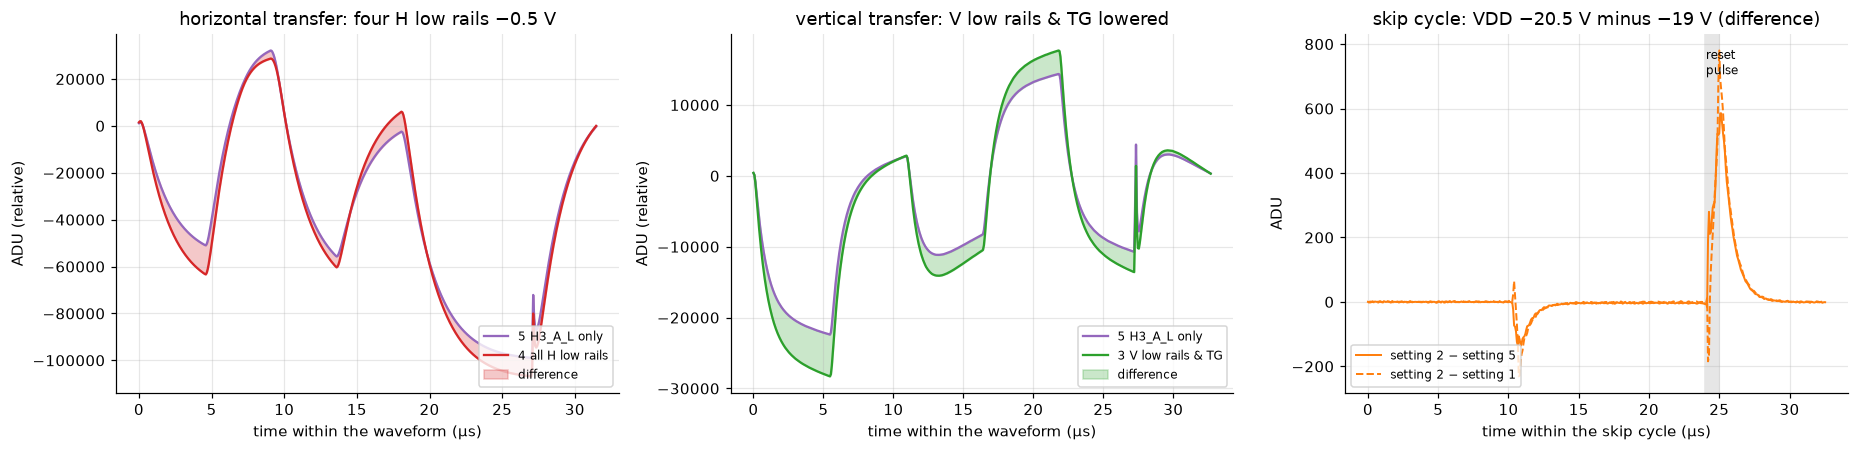

In [9]:
def mean_curve(group, ch, name):
    return np.mean([t["curves"][name] for t in traces if t["group"] == group and t["ch"] == ch], axis=0)

PANELS = [("horizontal: mean shape", 5, 4, "horizontal transfer: four H low rails −0.5 V", None),
          ("vertical: mean shape", 5, 3, "vertical transfer: V low rails & TG lowered", None)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (name, a, b, title, zoom) in zip(axes, PANELS):
    ca, cb = mean_curve(a, 0, name), mean_curve(b, 0, name)
    x = np.arange(len(ca)) / 15.0                                     # 15 samples per µs
    sl = slice(*zoom) if zoom else slice(None)
    ax.plot(x[sl], ca[sl], color=COLOR[a], lw=1.5, label=LABEL[a])
    ax.plot(x[sl], cb[sl], color=COLOR[b], lw=1.5, label=LABEL[b])
    ax.fill_between(x[sl], ca[sl], cb[sl], color=COLOR[b], alpha=0.25, label="difference")
    ax.set(title=title, xlabel="time within the waveform (µs)", ylabel="ADU (relative)")
    ax.legend(fontsize=8, loc="lower right")
# VDD: too small to see by eye, so show the difference itself, from both VDD comparisons
ax = axes[2]
for a, b, ls in [(5, 2, "-"), (1, 2, "--")]:
    diff = mean_curve(b, 0, "skip: mean shape") - mean_curve(a, 0, "skip: mean shape")
    ax.plot(np.arange(len(diff)) / 15.0, diff, ls, color=COLOR[2], lw=1.3, label=f"setting {b} − setting {a}")
ax.axvspan(24.0, 25.0, color="0.9", zorder=0); ax.text(24.05, ax.get_ylim()[1] * 0.85, "reset\npulse", fontsize=8)
ax.set(title="skip cycle: VDD −20.5 V minus −19 V (difference)", xlabel="time within the skip cycle (µs)", ylabel="ADU")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); save(fig, "waveforms"); plt.show()

* **Horizontal:** with lower H rails, every negative swing goes deeper. With H3_A_L alone (setting 5),
  only the swings driven by that phase change (setting 5 vs 2 shows this).
* **Vertical:** lower V rails & TG deepen the first part of the vertical waveform by about 5,000 ADU.
* **Skip cycle (VDD):** the difference is only a few hundred ADU on a 46,000 ADU pulse, so it is
  shown as a difference. Both VDD comparisons give the same shape: a higher pulse and a slower tail
  after it, i.e. a slower amplifier. The rest of the cycle is unchanged.

## 6. Noise, and do the images agree?

Left: the trace noise (CDS noise per skip). Right: the image noise (robust scatter of the overscan,
the last 6 columns, 500-skip average). Only settings 1–4 have an image. Note the log scales.

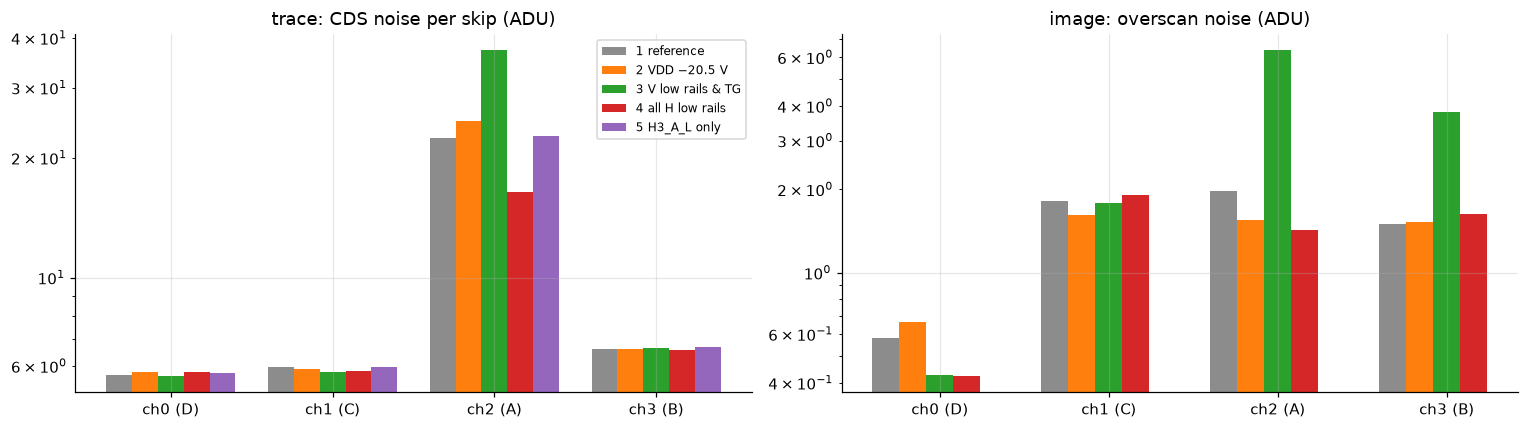

setting                ch    overscan level  overscan noise  charge per bin
1 reference            0              13.29            0.58           27.21
2 VDD −20.5 V          0              13.34            0.66           27.91
3 V low rails & TG     0              13.54            0.43           27.35
4 all H low rails      0              11.97            0.42           27.46
1 reference            1              16.54            1.81           29.54
2 VDD −20.5 V          1              16.26            1.62           30.23
3 V low rails & TG     1              16.85            1.78           29.03
4 all H low rails      1              14.69            1.91           30.21
1 reference            2              14.97            1.98           42.89
2 VDD −20.5 V          2              15.08            1.55           44.28
3 V low rails & TG     2              25.85            6.35           37.33
4 all H low rails      2              13.65            1.42           42.66
1 reference 

In [10]:
from astropy.io import fits
images, rows = {}, []
for g, group in enumerate(groups, start=1):
    for m, p in group["files"]:
        f = RUN / f"avg_{p.stem}.fits.bz2"
        if p.name.startswith("img_") and f.exists():
            images[g] = fits.open(f)
for g, hdul in images.items():
    for ch in range(4):
        d = hdul[ch + 1].data.astype(float)[2:]                       # first 2 rows left out (start-up)
        over, act = d[:, -6:], d[:, :-7]
        level = np.median(over)
        rows.append(dict(group=g, ch=ch, level=level, noise=1.4826 * np.median(np.abs(over - level)),
                         charge=np.median(act - level)))
def image(g, ch, key):
    return next(r[key] for r in rows if r["group"] == g and r["ch"] == ch)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
w = 0.16
for k, g in enumerate(range(1, 6)):
    x = np.arange(4) + (k - 2) * w
    axes[0].bar(x, [np.mean(values(g, ch, "skip: CDS rms (detrended)")) for ch in range(4)], w, color=COLOR[g], label=LABEL[g])
    if g in images:
        axes[1].bar(x, [image(g, ch, "noise") for ch in range(4)], w, color=COLOR[g], label=LABEL[g])
for ax, title in zip(axes, ["trace: CDS noise per skip (ADU)", "image: overscan noise (ADU)"]):
    ax.set_xticks(range(4)); ax.set_xticklabels([CHANNEL[c] for c in range(4)]); ax.set_yscale("log"); ax.set_title(title)
axes[0].legend(fontsize=8)
plt.tight_layout(); save(fig, "noise_trace_and_image"); plt.show()

print(f"{'setting':22s} {'ch':4s} {'overscan level':>15s} {'overscan noise':>15s} {'charge per bin':>15s}")
for r in sorted(rows, key=lambda r: (r["ch"], r["group"])):
    print(f"{LABEL[r['group']]:22s} {r['ch']:<4d} {r['level']:15.2f} {r['noise']:15.2f} {r['charge']:15.2f}")

* **Channel 2 (amplifier A) is the noisy one** in both traces and images. In setting 3 (V rails & TG,
  with the inverted TG_B) its noise rises in **both**: trace 25 → 37 ADU, image 1.6 → 6.3 ADU.
  Channel 3 (B) rises in the image as well (1.5 → 3.8 ADU).
* Lowering the H rails (setting 4) shifts the overscan level of all channels down by 1.2–1.9 ADU. The
  traces show the matching baseline shift.
* The charge per bin barely changes. These parameter changes did not change the dark charge visibly
  in 20×20 bins.

## 7. Could an ML model be trained on data like this?

Two separate questions.

**(a) Do the traces carry the information?** Test: can the features alone tell which setting a
trace set came from? Each trace set is left out in turn, the settings' average features are learned
from the others, and the left-out set is assigned to the nearest one. Each feature is measured in units
of its repeat scatter (pooled over the settings), and the distance is the **median** over the features
of the squared difference. This is about the simplest possible "model".

In [11]:
def leave_one_out(ch, combine=np.median, groups_used=(2, 3, 4, 5)):
    rows_ = [t for t in traces if t["ch"] == ch and t["group"] in groups_used]
    X = np.array([[t["features"][n] for n in names] for t in rows_]); y = np.array([t["group"] for t in rows_])
    X = X[:, np.all(np.isfinite(X), axis=0)]
    correct, mistakes = 0, []
    for i in range(len(y)):
        train = np.arange(len(y)) != i
        settings = sorted(set(y[train]))
        centres = {g: X[train & (y == g)].mean(0) for g in settings}
        residuals = np.concatenate([X[train & (y == g)] - centres[g] for g in settings])
        scatter = np.sqrt((residuals ** 2).sum(0) / (train.sum() - len(settings))) + 1e-12   # pooled repeat scatter
        distance = {g: combine(((X[i] - centres[g]) / scatter) ** 2) for g in settings}
        guess = min(distance, key=distance.get)
        correct += guess == y[i]
        if guess != y[i]:
            mistakes.append(f"{y[i]}→{guess}")
    return correct, len(y), mistakes
for combine in (np.median, np.sum):
    print(f"distance = {combine.__name__} over the features:")
    for ch in range(4):
        c, n, wrong = leave_one_out(ch, combine)
        print(f"   channel {ch}: {c} of {n} left-out trace sets assigned to the right setting  {wrong if wrong else ''}")

distance = median over the features:
   channel 0: 11 of 12 left-out trace sets assigned to the right setting  ['5→3']
   channel 1: 10 of 12 left-out trace sets assigned to the right setting  ['5→3', '5→3']
   channel 2: 12 of 12 left-out trace sets assigned to the right setting  
   channel 3: 11 of 11 left-out trace sets assigned to the right setting  
distance = sum over the features:
   channel 0: 12 of 12 left-out trace sets assigned to the right setting  
   channel 1: 11 of 12 left-out trace sets assigned to the right setting  ['5→2']
   channel 2: 12 of 12 left-out trace sets assigned to the right setting  
   channel 3: 11 of 11 left-out trace sets assigned to the right setting  


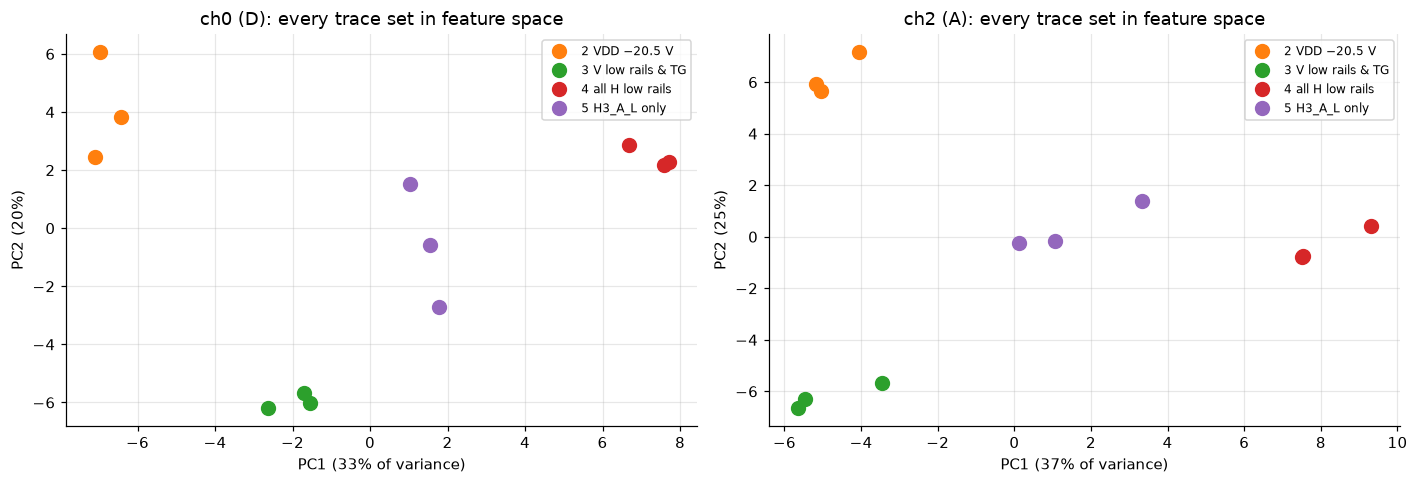

In [12]:
# a picture of the same: the two main directions (principal components) of the 85 features, channel 0
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, ch in zip(axes, (0, 2)):
    sel = [t for t in traces if t["ch"] == ch and t["group"] >= 2]
    X = np.array([[t["features"][n] for n in names] for t in sel]); X = X[:, np.all(np.isfinite(X), axis=0)]
    Z = (X - X.mean(0)) / (X.std(0) + 1e-12)
    U, s, Vt = np.linalg.svd(Z, full_matrices=False)
    P = Z @ Vt[:2].T
    for t, (px, py) in zip(sel, P):
        ax.plot(px, py, "o", color=COLOR[t["group"]], ms=9, label=LABEL[t["group"]])
    h, l = ax.get_legend_handles_labels(); keep = dict(zip(l, h))
    ax.legend(keep.values(), keep.keys(), fontsize=8)
    ax.set(title=f"{CHANNEL[ch]}: every trace set in feature space", xlabel=f"PC1 ({s[0]**2 / np.sum(s**2):.0%} of variance)",
           ylabel=f"PC2 ({s[1]**2 / np.sum(s**2):.0%})")
plt.tight_layout(); save(fig, "feature_space"); plt.show()


### The PCA in detail

For one channel, write the features of the $n = 12$ trace sets (settings 2–5) as a matrix
$X$ ($n \times p$, one row per trace set, one column per feature; $p = 83$ finite features).

1. **Standardize each feature** (column $k$) with its mean and standard deviation over the 12 trace
   sets:
   $$z_{ik} = \frac{x_{ik} - \bar x_k}{\sigma_k}, \qquad \bar x_k = \frac1n\sum_i x_{ik}, \qquad
   \sigma_k^2 = \frac1n \sum_i (x_{ik}-\bar x_k)^2 .$$
   Every feature then has mean 0 and variance 1, whatever its unit (ADU, µs, a ratio). Without this,
   the features with the largest numbers (ADU levels of 10⁴–10⁵) would make up the whole PCA. A
   feature that is identical in all 12 trace sets ($\sigma_k = 0$) is set to 0 and plays no part. Here
   these are two discrete counts that are 0 everywhere, and the first-skip ringing frequency, whose fit
   returns exactly 0.01 cycles/skip for every trace: it sits at a fixed value and carries no
   information.
2. **Correlation matrix** $R = Z^\top Z / n$ ($p\times p$): $R_{kl}$ is the correlation between
   features $k$ and $l$ over the 12 trace sets. Its trace is the number of features that vary.
3. **Principal components** are the eigenvectors $v_1, v_2, \dots$ of $R$ (unit length, mutually
   orthogonal), ordered by eigenvalue $\lambda_1 \ge \lambda_2 \ge \dots$. In practice they come from the
   singular-value decomposition $Z = U S V^\top$: $v_j$ = column $j$ of $V$, $\lambda_j = s_j^2/n$.
4. **Scores**: trace set $i$ is drawn at $(t_{i1}, t_{i2})$ with $t_{ij} = z_i \cdot v_j = \sum_k z_{ik} v_{jk}$.
   The weights $v_{jk}$ are the **loadings**: how much feature $k$ contributes to component $j$.
5. **Fraction of the spread** held by component $j$: $\lambda_j / \sum_l \lambda_l$ (the percentages on
   the axes).

With 12 trace sets there are at most $n - 1 = 11$ components with non-zero eigenvalue. The
standardization uses the **total** spread over all settings, not the repeat scatter of Test 1. The
PCA does not know which setting a trace set belongs to: that the settings come out as separate
clusters is a result, not an input.


ch0 (D): 83 finite features, 2 constant (discrete: CDS outlier fraction, discrete: within-cycle spectrum lines), trace of R = 81.0; non-zero eigenvalues: 11
   eigenvalues λ1..λ5: [26.7 16.   9.4  6.   5.6]  fractions: [0.33  0.198 0.116 0.074 0.069]  cumulative: [0.33  0.528 0.643 0.717 0.786]
   2 VDD −20.5 V          centre (PC1, PC2) = (-6.83, +4.12), repeat scatter (0.36, 1.82)
   3 V low rails & TG     centre (PC1, PC2) = (-1.95, -5.96), repeat scatter (0.59, 0.25)
   4 all H low rails      centre (PC1, PC2) = (+7.33, +2.44), repeat scatter (0.56, 0.38)
   5 H3_A_L only          centre (PC1, PC2) = (+1.45, -0.60), repeat scatter (0.37, 2.12)
   PC1 largest loadings: horizontal: maximum (-0.18), edge: rise time (ns) (-0.18), horizontal: minimum (-0.17), slow: row-start recovery amplitude (ADU) (-0.17), slow: H-transfer first-to-last change (ADU) (+0.17)
   PC2 largest loadings: noise: window-length ratio 75/150 (-0.22), vertical: minimum (+0.21), noise: signal-window settling (ADU

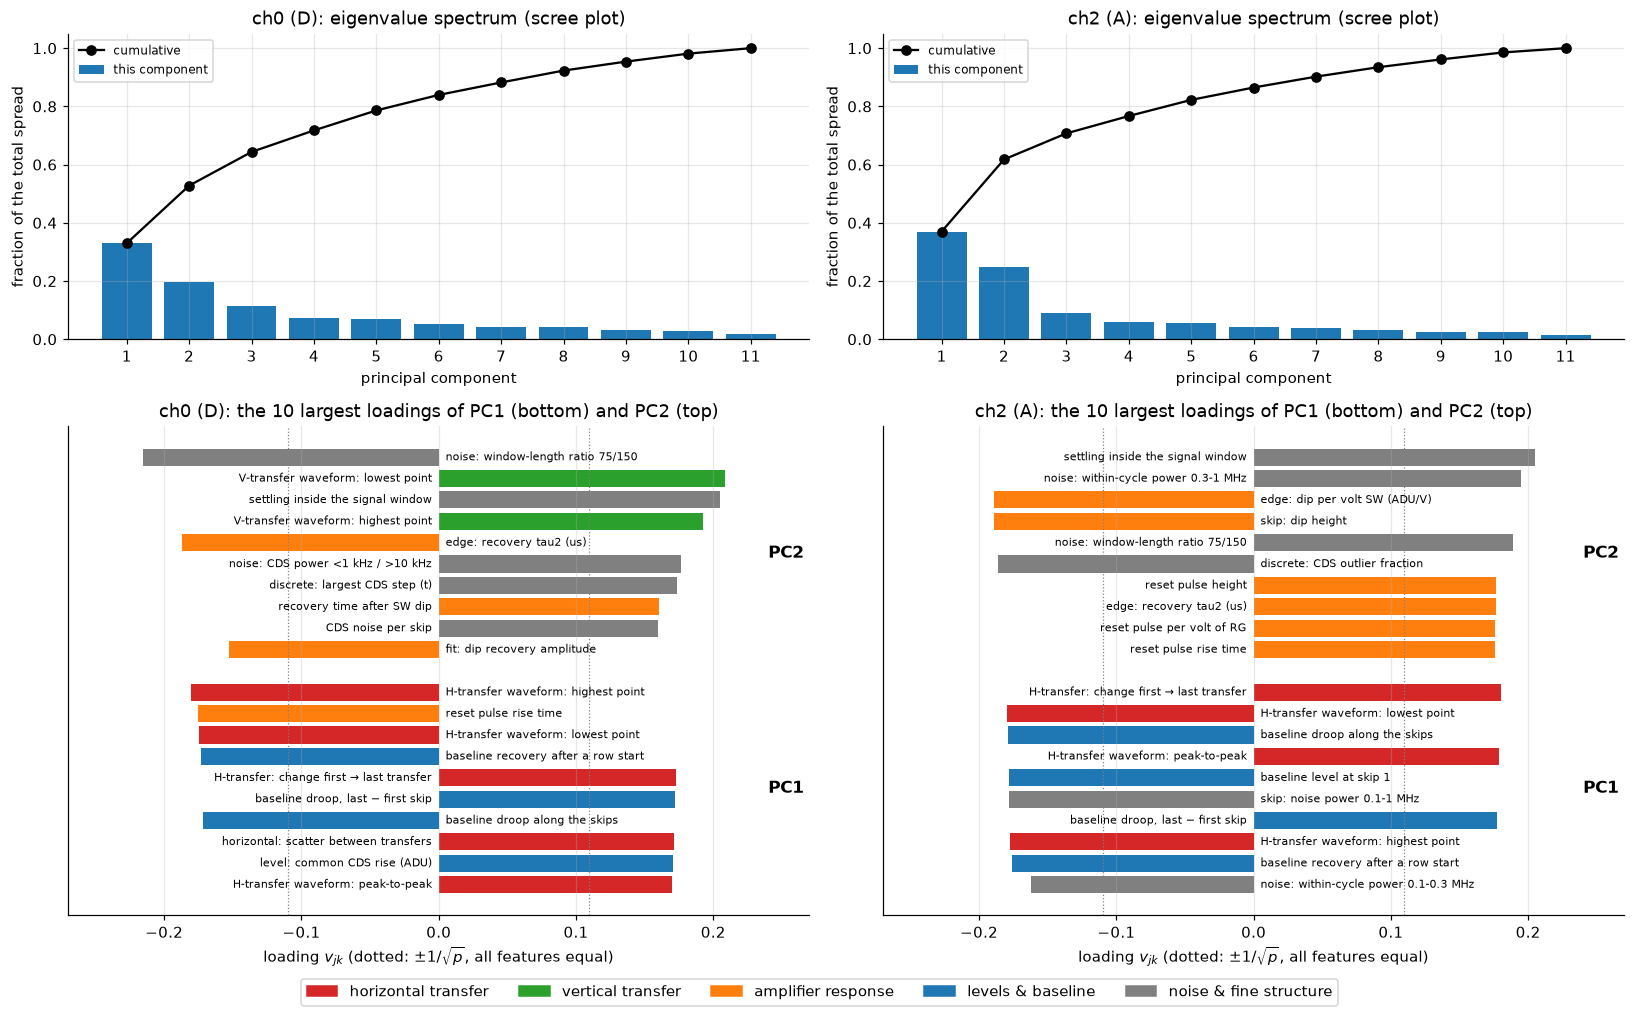

In [13]:

def pca(ch):
    sel = [t for t in traces if t["ch"] == ch and t["group"] >= 2]
    X = np.array([[t["features"][n] for n in names] for t in sel])
    keep = np.all(np.isfinite(X), axis=0)
    X, used = X[:, keep], [n for n, k in zip(names, keep) if k]
    sigma = X.std(0)
    constant = sigma <= 1e-12 * (np.abs(X.mean(0)) + 1)          # identical in all trace sets (up to rounding)
    Z = np.where(constant, 0.0, (X - X.mean(0)) / np.where(constant, 1, sigma))   # constant features stay 0
    U, s, Vt = np.linalg.svd(Z, full_matrices=False)
    lam = s ** 2 / len(sel)
    return dict(sel=sel, used=used, sigma=sigma, constant=constant, Z=Z, lam=lam, frac=lam / lam.sum(), V=Vt, T=Z @ Vt[:2].T)

fig, axes = plt.subplots(2, 2, figsize=(15, 9), gridspec_kw={"height_ratios": [1, 1.6]})
for col, ch in enumerate((0, 2)):
    r = pca(ch)
    print(f"{CHANNEL[ch]}: {len(r['used'])} finite features, {int(np.sum(r['constant']))} constant "
          f"({', '.join(n for n, k in zip(r['used'], r['constant']) if k)}), "
          f"trace of R = {r['lam'].sum():.1f}; non-zero eigenvalues: {int(np.sum(r['lam'] > 1e-9 * r['lam'][0]))}")
    print("   eigenvalues λ1..λ5:", np.round(r["lam"][:5], 1), " fractions:", np.round(r["frac"][:5], 3),
          " cumulative:", np.round(np.cumsum(r["frac"])[:5], 3))
    y = np.array([t["group"] for t in r["sel"]])
    for g in sorted(set(y)):
        centre, spread = r["T"][y == g].mean(0), r["T"][y == g].std(0, ddof=1)
        print(f"   {LABEL[g]:22s} centre (PC1, PC2) = ({centre[0]:+5.2f}, {centre[1]:+5.2f}), "
              f"repeat scatter ({spread[0]:.2f}, {spread[1]:.2f})")
    for j in (0, 1):
        top = np.argsort(-np.abs(r["V"][j]))[:5]
        print(f"   PC{j + 1} largest loadings:", ", ".join(f"{r['used'][k]} ({r['V'][j][k]:+.2f})" for k in top))
    ax = axes[0, col]
    k = np.arange(1, 12)
    ax.bar(k, r["frac"][:11], color="tab:blue", label="this component")
    ax.plot(k, np.cumsum(r["frac"][:11]), "o-", color="k", label="cumulative")
    ax.set(xticks=k, xlabel="principal component", ylabel="fraction of the total spread",
           title=f"{CHANNEL[ch]}: eigenvalue spectrum (scree plot)", ylim=(0, 1.05))
    ax.legend(fontsize=8)
    ax = axes[1, col]
    for j, shift, colour in ((0, -0.2, "tab:purple"), (1, 0.2, "tab:cyan")):
        top = np.argsort(-np.abs(r["V"][j]))[:10][::-1]
        ax.barh(np.arange(10) + (0 if j == 0 else 11), r["V"][j][top],
                color=[RCOLOR[region(r["used"][q])] for q in top])
        for yy, q in zip(np.arange(10) + (0 if j == 0 else 11), top):
            ax.text(0.005 if r["V"][j][q] < 0 else -0.005, yy, PLAIN.get(r["used"][q], r["used"][q]), fontsize=7,
                    va="center", ha="left" if r["V"][j][q] < 0 else "right")
        ax.text(0.24, (4.5 if j == 0 else 15.5), f"PC{j + 1}", fontsize=11, fontweight="bold", va="center")
    ax.axvline(1 / np.sqrt(len(r["used"])), color="0.5", ls=":", lw=0.8)
    ax.axvline(-1 / np.sqrt(len(r["used"])), color="0.5", ls=":", lw=0.8)
    ax.set(yticks=[], xlim=(-0.27, 0.27), xlabel="loading $v_{jk}$ (dotted: $\\pm 1/\\sqrt{p}$, all features equal)",
           title=f"{CHANNEL[ch]}: the 10 largest loadings of PC1 (bottom) and PC2 (top)")
handles = [plt.Rectangle((0, 0), 1, 1, color=RCOLOR[q]) for q in REGIONS]
fig.legend(handles, REGIONS, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.03))
plt.tight_layout(); save(fig, "pca_details"); plt.show()



**Reading it.**

* The first two components hold 54 % (ch0) and 63 % (ch2) of the spread. The rest is shared
  over 9 more components, which also hold the scatter between repeats.
* **The loadings are spread over many features.** The largest are 0.18–0.21, compared with
  $1/\sqrt p \approx 0.11$ if every feature counted equally. So a component is a broad combination
  of many correlated features, not one feature:
  * **PC1** is mostly horizontal-transfer and baseline features (the H low rails). On ch0 its score
    correlates with the H-transfer lowest point at $r = -0.92$.
  * **PC2** mixes the vertical-transfer and amplifier-response features. It separates the V rails &
    TG setting (bottom) from the VDD setting (top).
* In the score plot, the setting centres are 5–14 units apart, while the repeats scatter by 0.2–2
  units around them.


**(a) Yes.** With the median distance, 46 of the 47 left-out trace sets are assigned to the right
setting, and in the picture each setting forms its own cluster: the features record the operating
parameters reproducibly.

The sum distance makes 3 mistakes, and they are informative: with only 3 repeats per setting, the
scatter of some features is under-estimated, and those features then dominate a sum over 85 features.
A real model will need **feature selection or robust weighting, and more repeats** (the planned 3
reference + 3 θ trace sets per packet help here).

**(b) Is this enough data to train the model we want (parameters → σe, λ, gain)? No.** The data
were not designed for that:

| Need | This run |
|---|---|
| many distinct parameter sets (rule of thumb ≥ 10 per varied parameter, so about 100+) | **5** |
| one parameter at a time, or a design where the changes can be separated | rails changed in blocks; VDD and H3_A_L, and NCOLPRE and VDD, are confounded |
| image labels (σe, λ, gain from WADERs) for every packet | **none**: 20×20 binned images hold 20–35 e⁻ per bin, so WADERs cannot fit them |
| labels that actually vary | image noise changed only in setting 3 (with the TG_B rail inverted), dark charge not visibly |
| repeated references to measure drift | none (the settings are up to 85 min apart) |

**What this run does give us:**

1. **Trace features are good inputs.** They respond strongly (separations 10–400), only to the
   relevant parameter, and agree between repeats.
2. **A noise model for every feature** (the repeat scatter), which the model needs for weighting.
3. **A first trace ↔ image link:** channel 2's noise rises in both.
4. **A design lesson:** set all trace cuts, take a reference in every packet, and change one parameter
   (or a random combination) per packet over a range wide enough to move σe.

**What would make it trainable.** Packets taken with `take_packet.py` (reference traces in every
packet, explicit cuts) and the 1×1 image of the session notes. That is about 10 minutes per packet,
so about 6 per hour and about 80–100 in an overnight run. As a first step, scan about 5 parameters
over about 5 values each (one-at-a-time, 25 packets). Then do a random design over the same
parameters (about 50–100 packets). That is the size where a Gaussian-process or small boosted-tree
model of σe(θ, trace features) becomes meaningful.

## Appendix: all 85 features

Median separation over the 4 channels for the three comparisons, grouped by kind of feature. This
is for completeness; sections 4–5 show the important ones.

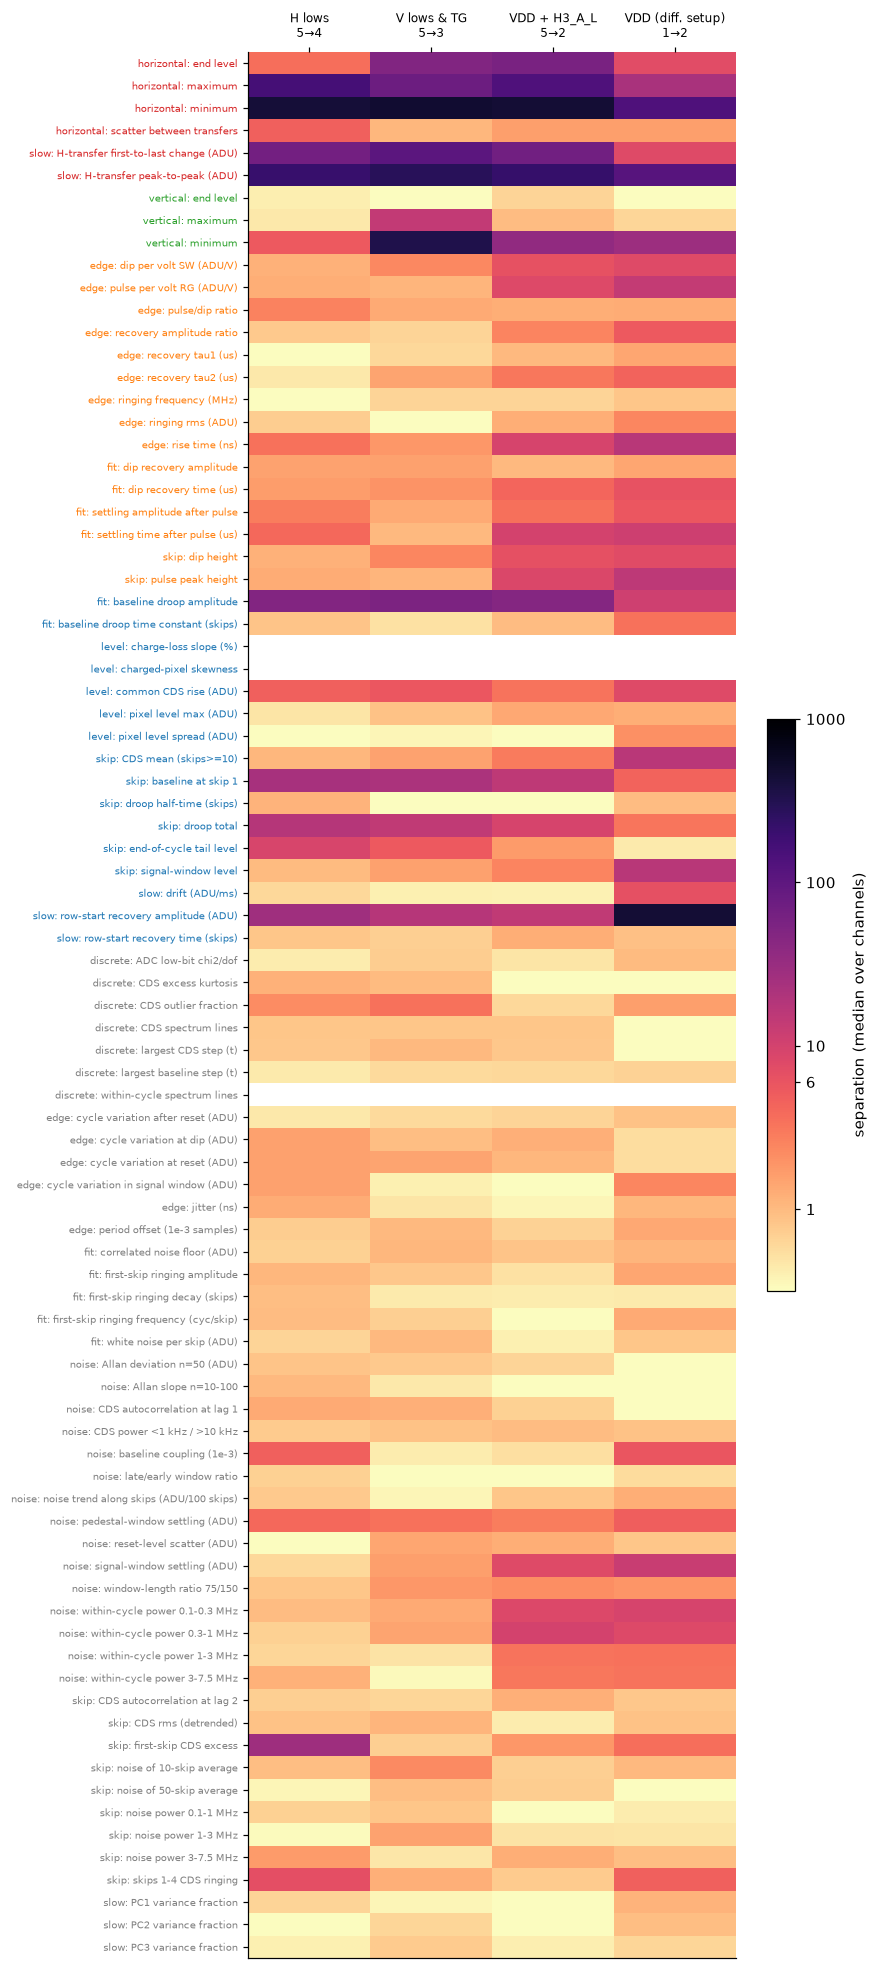

In [14]:
comps = [(5, 4), (5, 3), (5, 2), (1, 2)]
titles = ["H lows\n5→4", "V lows & TG\n5→3", "VDD + H3_A_L\n5→2", "VDD (diff. setup)\n1→2"]
order = sorted(range(len(names)), key=lambda i: (REGIONS.index(region(names[i])), names[i]))
M = np.array([[np.nanmedian(np.abs(compare(a, b)[0][:, i])) for a, b in comps] for i in order])
fig, ax = plt.subplots(figsize=(8, 18))
im = ax.imshow(np.log10(np.clip(M, 0.3, 1000)), cmap="magma_r", aspect="auto", vmin=-0.5, vmax=3)
ax.set_xticks(range(len(comps))); ax.set_xticklabels(titles, fontsize=8); ax.xaxis.tick_top()
ax.set_yticks(range(len(order))); ax.set_yticklabels([names[i] for i in order], fontsize=6.5)
for tick, i in zip(ax.get_yticklabels(), order):
    tick.set_color(RCOLOR[region(names[i])])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.3, ticks=[0, np.log10(6), 1, 2, 3])
cb.ax.set_yticklabels(["1", "6", "10", "100", "1000"]); cb.set_label("separation (median over channels)")
plt.tight_layout(); save(fig, "all_features"); plt.show()